# arXiv embeddings at scale

This notebook consumes the sample and text-vector cache made by [Prepare the arXiv dataset](../data/arxiv/prepare_arxiv_dataset.ipynb). It fits one UMAP embedding and one multilevel-initialized IMSTE embedding using the selected metric, then caches both layouts for exploration in notebook 04.


## 1. Load the prepared dataset

Run `../data/arxiv/prepare_arxiv_dataset.ipynb` first if there is no cache or if you want a larger sample. Here, increasing or changing model settings does not download or re-embed text; this notebook reads the one prepared cache.

In [1]:
%load_ext autoreload
%autoreload 2

%config InlineBackend.figure_format = 'retina'

from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "pyproject.toml").exists() and (PROJECT_ROOT.parent / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "notebooks" / "src"))
DATA_DIR = PROJECT_ROOT / "data" / "arxiv"
CACHE_DIR = DATA_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
from arxiv_dataset import load_arxiv_dataset
papers, X, data_manifest = load_arxiv_dataset(DATA_DIR)
print(f"Loaded {len(papers):,} papers × {X.shape[1]:,} features")
print(f"Vector matrix in memory: {X.nbytes / 1024**3:.2f} GiB")
print("Dataset cache ID:", data_manifest["dataset_id"])


Loaded 160,000 papers × 384 features
Vector matrix in memory: 0.23 GiB
Dataset cache ID: 4c48116cdd83164fc19e


## 2. Prepare category labels

In [2]:
primary_category = papers["categories"].fillna("unknown").str.split().str[0]
archive = primary_category.str.split(".").str[0]
domain_names = {
    "cs": "computer science",
    "math": "mathematics",
    "eess": "engineering",
    "stat": "statistics",
    "q-bio": "biology",
    "q-fin": "finance",
    "econ": "economics",
}
domain = archive.map(domain_names).fillna("physics")
domain_order = domain.value_counts().index.tolist()
labels = pd.Categorical(domain, categories=domain_order)
display(pd.DataFrame({"primary_category": primary_category, "domain": domain}).groupby("domain", observed=True).size().sort_values(ascending=False).rename("papers"))

domain
physics             77392
computer science    41554
mathematics         30343
engineering          4224
statistics           3287
biology              1831
finance               739
economics             630
Name: papers, dtype: int64

## 3. Fit UMAP and multilevel IMSTE

Set the shared metric and projection settings, then run the UMAP and IMSTE fit cells separately. A matching cache loads both embeddings; otherwise each cell fits its method and the IMSTE cell saves the pair.

In [3]:
import hashlib
import umap

RANDOM_STATE = int(data_manifest["random_state"])
METRIC = "euclidean"  # or "cosine"
N_NEIGHBORS = 15
UMAP_EPOCHS = 200
UMAP_REPULSION_STRENGTH = 8

IMSTE_N_MSTS = 4
IMSTE_N_EPOCHS = 500
IMSTE_NEGATIVE_RATIO = 1
IMSTE_LAMBDA_REP = 0.5
IMSTE_MST_METHOD = "famst"
IMSTE_MST_NEIGHBORS = 15
IMSTE_DEVICE = "mps"
MULTILEVEL_REDUCTION_RATIO = 4
MULTILEVEL_BASE_SIZE = 1024
MULTILEVEL_EPOCHS = 10

projection_settings = {
    "data_id": data_manifest["dataset_id"],
    "metric": METRIC,
    "umap": [N_NEIGHBORS, UMAP_EPOCHS, UMAP_REPULSION_STRENGTH, 0.1, METRIC, "rinnd", RANDOM_STATE],
    "imste": [IMSTE_N_MSTS, IMSTE_N_EPOCHS, IMSTE_NEGATIVE_RATIO, IMSTE_LAMBDA_REP,
              IMSTE_MST_METHOD, IMSTE_MST_NEIGHBORS, IMSTE_DEVICE, METRIC, RANDOM_STATE],
    "multilevel": [MULTILEVEL_REDUCTION_RATIO, MULTILEVEL_BASE_SIZE, MULTILEVEL_EPOCHS],
}
projection_id = hashlib.sha256(json.dumps(projection_settings, sort_keys=True).encode()).hexdigest()[:16]
PROJECTION_CACHE = CACHE_DIR / "arxiv_embeddings.npz"
if PROJECTION_CACHE.is_file():
    with np.load(PROJECTION_CACHE, allow_pickle=False) as saved:
        cache_hit = str(saved["projection_id"].item()) == projection_id
else:
    cache_hit = False

if cache_hit:
    with np.load(PROJECTION_CACHE, allow_pickle=False) as saved:
        Z_umap = saved["umap"]
        Z_imste = saved["imste_multilevel"]
        umap_seconds = float(saved["umap_seconds"])
        imste_seconds = float(saved["imste_seconds"])
    print("Loaded matching cached embeddings:", PROJECTION_CACHE)
else:
    print("No matching embedding cache; run the UMAP and IMSTE fit cells.")


No matching embedding cache; run the UMAP and IMSTE fit cells.


In [4]:
import time

if not cache_hit:
    umap_started = time.perf_counter()
    Z_umap = umap.UMAP(
        n_components=2,
        n_neighbors=N_NEIGHBORS,
        min_dist=0.1,
        repulsion_strength=UMAP_REPULSION_STRENGTH,
        metric=METRIC,
        compatibility_layout=False,
        nearest_neighbor_backend="rinnd",
        init="recursive",
        random_state=RANDOM_STATE,
        n_epochs=UMAP_EPOCHS,
        verbose=True,
    ).fit_transform(X)
    umap_seconds = time.perf_counter() - umap_started
    print(f"UMAP fit: {umap_seconds / 60:.1f} min")
else:
    print("Using cached UMAP embedding.")


UMAP(compatibility_layout=False, init='recursive', n_epochs=200, nearest_neighbor_backend='rinnd', random_state=42, repulsion_strength=8, verbose=True)
Thu Nov 12 12:44:32 2026 Construct fuzzy simplicial set
Thu Nov 12 12:44:32 2026 Finding Nearest Neighbors
Thu Nov 12 12:44:32 2026 Using RINND to find nearest neighbors
Building RP forest with 8 trees...
Initializing graph from 29798 leaves...
Running NN-descent for up to 17 iterations...
Iteration 1: 1568923 updates
Iteration 2: 994735 updates
Iteration 3: 272030 updates
Iteration 4: 64764 updates
Iteration 5: 17308 updates
Iteration 6: 5108 updates
Iteration 7: 1488 updates
Converged after 7 iterations

=== Timing Breakdown ===
Forest building:     225.344ms
Leaf initialization: 275.541ms
Candidate building:   59.144ms (7 iters)
Update iterations:   697.293ms (7 iters)
Total measured:     1257.322ms
Thu Nov 12 12:44:33 2026 Finished Nearest Neighbor Search
Thu Nov 12 12:44:35 2026 Construct embedding
Thu Nov 12 12:44:35 2026 Recursiv

Init recursion depth 4:   0%|          | 0/138 [00:00<?, ?it/s]

Init recursion depth 3:   0%|          | 0/98 [00:00<?, ?it/s]

Init recursion depth 2:   0%|          | 0/70 [00:00<?, ?it/s]

Init recursion depth 1:   0%|          | 0/50 [00:00<?, ?it/s]

Thu Nov 12 12:44:36 2026 Using adam layout optimizer


Epochs completed:   0%|            0/200 [00:00]

Thu Nov 12 12:44:40 2026 Finished embedding
UMAP fit: 0.1 min


In [5]:
import time

if not cache_hit:
    from imste._estimator import IteratedMinimumSpanningTreeEmbedder

    settings = dict(
        n_components=2, n_msts=IMSTE_N_MSTS, n_epochs=IMSTE_N_EPOCHS,
        negative_ratio=IMSTE_NEGATIVE_RATIO, lambda_rep=IMSTE_LAMBDA_REP,
        mst_method=IMSTE_MST_METHOD, mst_neighbors=IMSTE_MST_NEIGHBORS,
        metric=METRIC, random_state=RANDOM_STATE, device=IMSTE_DEVICE,
    )
    started = time.perf_counter()
    Z_imste = IteratedMinimumSpanningTreeEmbedder(
        **settings, multilevel_init=True,
        multilevel_reduction_ratio=MULTILEVEL_REDUCTION_RATIO,
        multilevel_base_size=MULTILEVEL_BASE_SIZE,
        multilevel_epochs=MULTILEVEL_EPOCHS,
    ).fit_transform(X)
    imste_seconds = time.perf_counter() - started
    print(f"Multilevel IMSTE fit: {imste_seconds / 60:.1f} min")

    temp_path = PROJECTION_CACHE.with_suffix(".tmp.npz")
    np.savez_compressed(
        temp_path, projection_id=np.asarray(projection_id),
        umap=np.asarray(Z_umap, dtype=np.float32),
        imste_multilevel=np.asarray(Z_imste, dtype=np.float32),
        labels=np.asarray(labels, dtype="U"),
        umap_seconds=np.asarray(umap_seconds), imste_seconds=np.asarray(imste_seconds),
        dataset_id=np.asarray(data_manifest["dataset_id"]),
        settings_json=np.asarray(json.dumps(projection_settings, sort_keys=True)),
    )
    temp_path.replace(PROJECTION_CACHE)
    print("Saved reusable projection cache:", PROJECTION_CACHE)
else:
    print("Using cached multilevel IMSTE embedding.")


Multilevel IMSTE fit: 0.9 min
Saved reusable projection cache: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/data/arxiv/cache/arxiv_embeddings.npz


## 4. Compare fit runtimes and render both embeddings

The runtime table is followed by side-by-side Datashader views using the same domain colors and raster settings.

In [6]:
runtime_summary = pd.DataFrame({
    "method": ["UMAP", "IMSTE · multilevel initialization"],
    "seconds": [umap_seconds, imste_seconds],
})
runtime_summary["runtime"] = runtime_summary["seconds"].map(
    lambda value: f"{value / 60:.1f} min" if value >= 60 else f"{value:.1f} s"
)
display(runtime_summary)


,method,seconds,runtime
0,UMAP,8.498660,8.5 s
1,IMSTE · multilevel initialization,55.686496,55.7 s


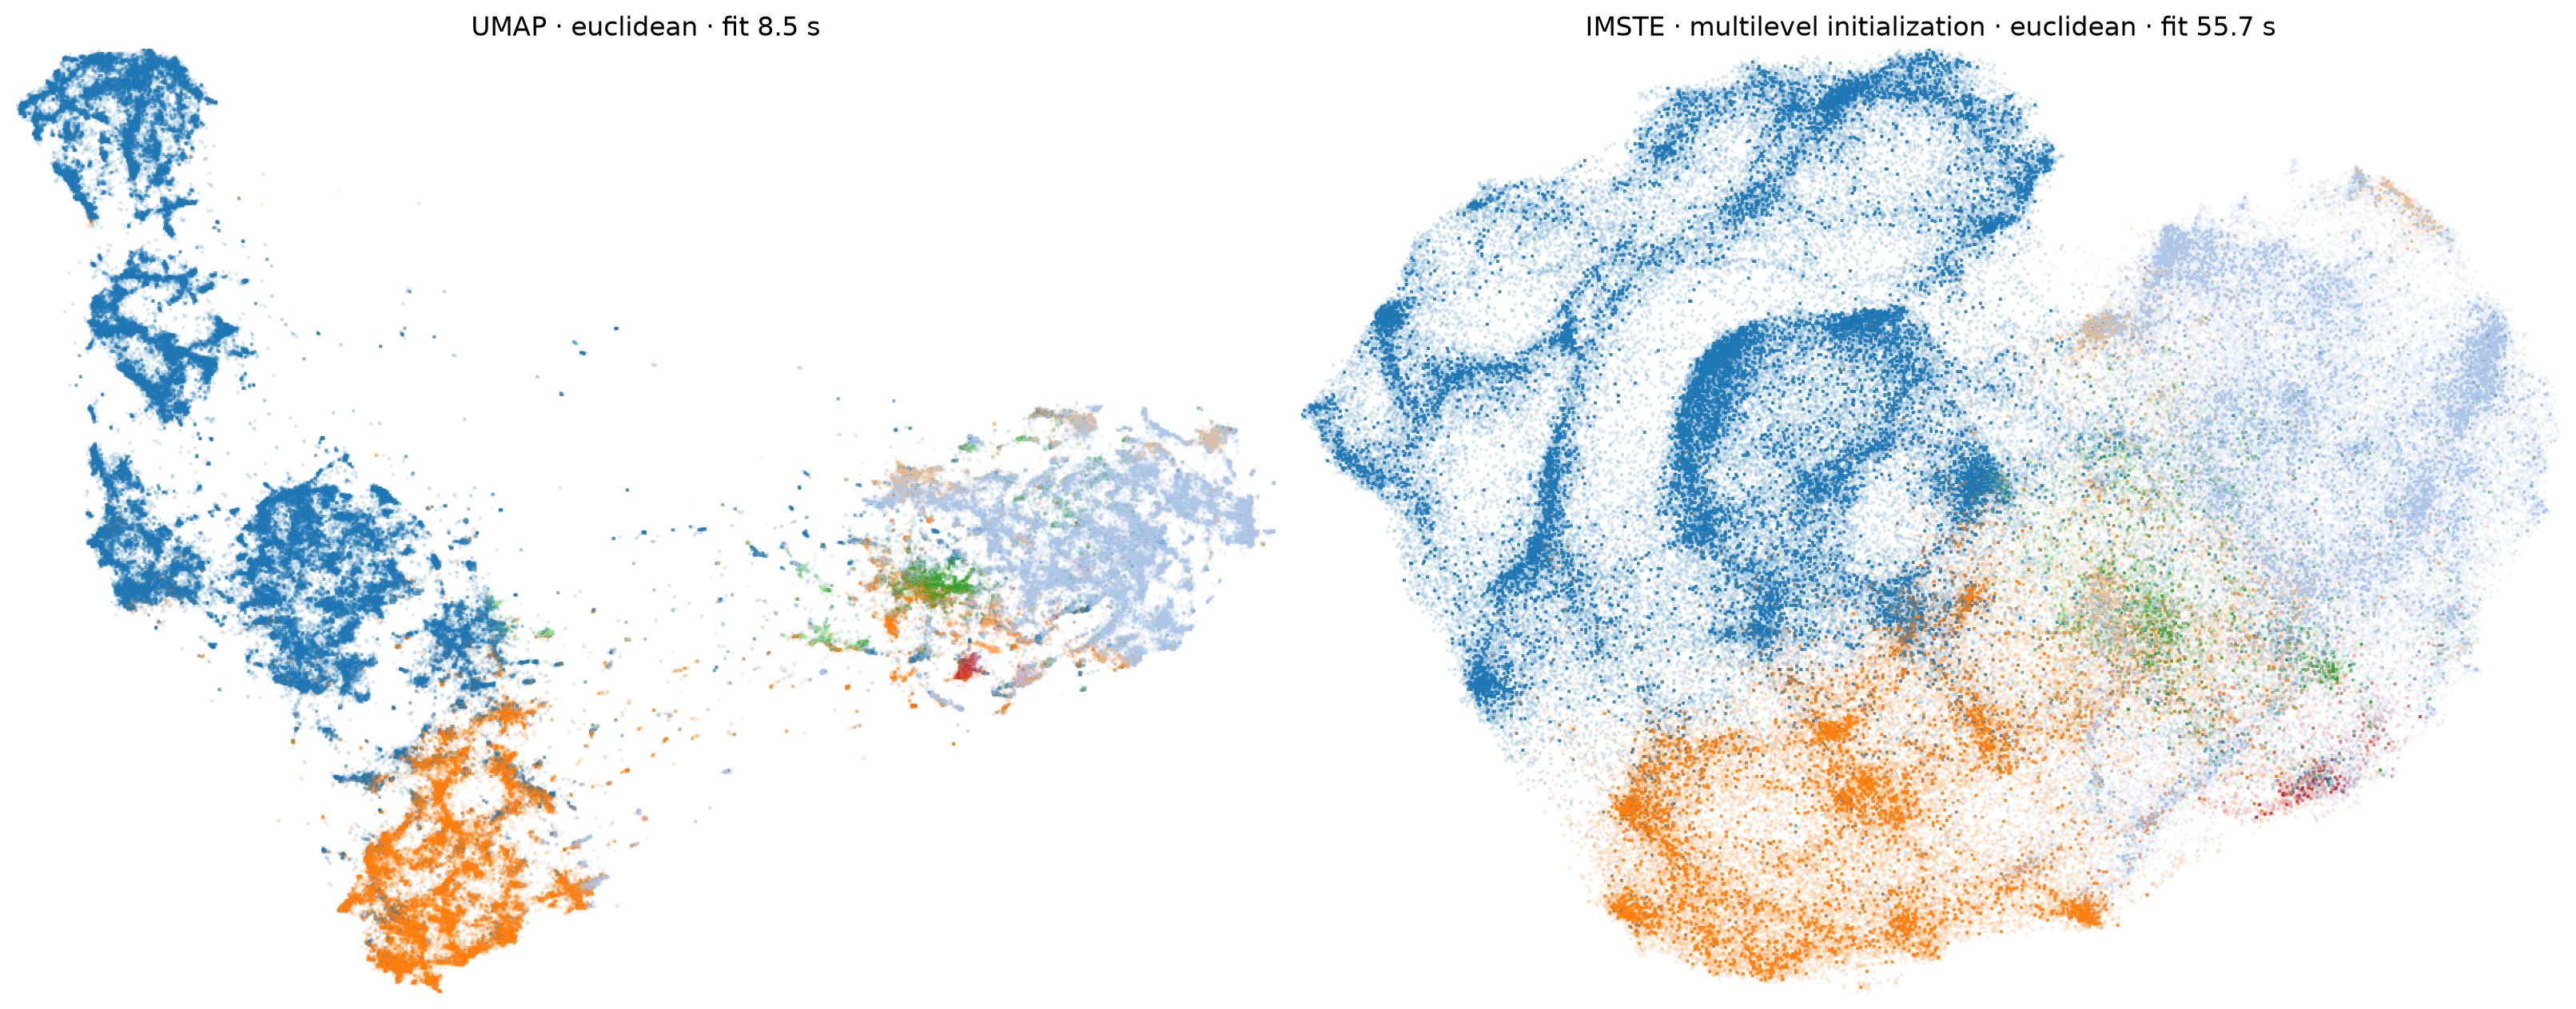

In [7]:
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from IPython.display import display
from imste.visualization import render_datashader_embedding

domain_order = list(labels.categories)
palette = plt.get_cmap("tab20")
domain_color_key = {
    domain: to_hex(palette(index % palette.N))
    for index, domain in enumerate(domain_order)
}
label_values = labels.astype(str)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
for ax, method, coordinates, seconds in zip(
    axes, ("UMAP", "IMSTE · multilevel initialization"),
    (Z_umap, Z_imste), (umap_seconds, imste_seconds),
):
    image = render_datashader_embedding(
        coordinates, label_values, width=1200, height=900,
        color_key=domain_color_key, min_alpha=40, background="white",
        spread_px=1,
    )
    ax.imshow(image.to_pil())
    runtime = f"{seconds / 60:.1f} min" if seconds >= 60 else f"{seconds:.1f} s"
    ax.set_title(f"{method} · {METRIC} · fit {runtime}")
    ax.set_axis_off()
display(fig)
plt.close(fig)
